In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

plt.style.use("seaborn-v0_8-whitegrid")

In [ ]:
from google.colab import drive
import os

try:
    drive.mount("/content/drive")
except Exception as e:
    print("Google Drive tidak dapat dimuat, menggunakan environment lokal.")

# Mencoba mencari di Google Drive, jika tidak ada cari di environment lokal
CSV_PATH = "/content/drive/MyDrive/Twitter_Sentiment_Macrofinance_Indonesia.csv"

if not os.path.exists(CSV_PATH):
    alternative_path = "/content/Sentiment_Macrofinance_Indonesia.csv"
    if os.path.exists(alternative_path):
        CSV_PATH = alternative_path
    else:
        raise FileNotFoundError(
            f"File tidak ditemukan di Google Drive ({CSV_PATH}) atau di lokal ({alternative_path}). "
            f"Silakan unggah file tersebut."
        )

print("Dataset siap dibaca dari:", CSV_PATH)

Mounted at /content/drive
Dataset siap dibaca dari: /content/Sentiment_Macrofinance_Indonesia.csv


In [ ]:
df = pd.read_csv(CSV_PATH)

required_columns = [
    "Date",
    "Econ-Neg",
    "Econ-Pos",
    "Net",
    "Econ-RPD",
    "Econ-Logit"
]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Kolom berikut tidak ditemukan: {missing_columns}")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

numeric_columns = required_columns[1:]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=required_columns)
      .sort_values("Date")
      .reset_index(drop=True)
)

print("Ukuran data:", df.shape)
print("Rentang tanggal:", df["Date"].min().date(), "s.d.", df["Date"].max().date())
display(df.head())

Ukuran data: (389, 6)
Rentang tanggal: 2020-04-09 s.d. 2021-05-31


,Date,Econ-Neg,Econ-Pos,Net,Econ-RPD,Econ-Logit
0,2020-04-09,1074,1035,1194,-0.018492,-0.016056
1,2020-04-10,15303,6199,24283,-0.423402,-0.392434
2,2020-04-11,16804,5511,16002,-0.506072,-0.484156
3,2020-04-12,16430,6543,13197,-0.430375,-0.399841
4,2020-04-13,19198,7668,16663,-0.429167,-0.398557


In [ ]:
display(df[required_columns[1:]].describe().T)
print("Jumlah nilai kosong:")
display(df[required_columns].isna().sum())

,count,mean,std,min,25%,50%,75%,max
Econ-Neg,389.0,14147.411311,6961.997346,1074.000000,10048.000000,12705.000000,16488.000000,87228.000000
Econ-Pos,389.0,7336.848329,3973.442977,618.000000,5210.000000,6310.000000,8266.000000,43131.000000
Net,389.0,11560.023136,5084.929845,1194.000000,8281.000000,10280.000000,13493.000000,39420.000000
Econ-RPD,389.0,-0.309680,0.181084,-0.719093,-0.426399,-0.320414,-0.218165,0.391121
Econ-Logit,389.0,-0.288307,0.178397,-0.786704,-0.395609,-0.288447,-0.192584,0.358827


Jumlah nilai kosong:


,0
Date,0
Econ-Neg,0
Econ-Pos,0
Net,0
Econ-RPD,0
Econ-Logit,0


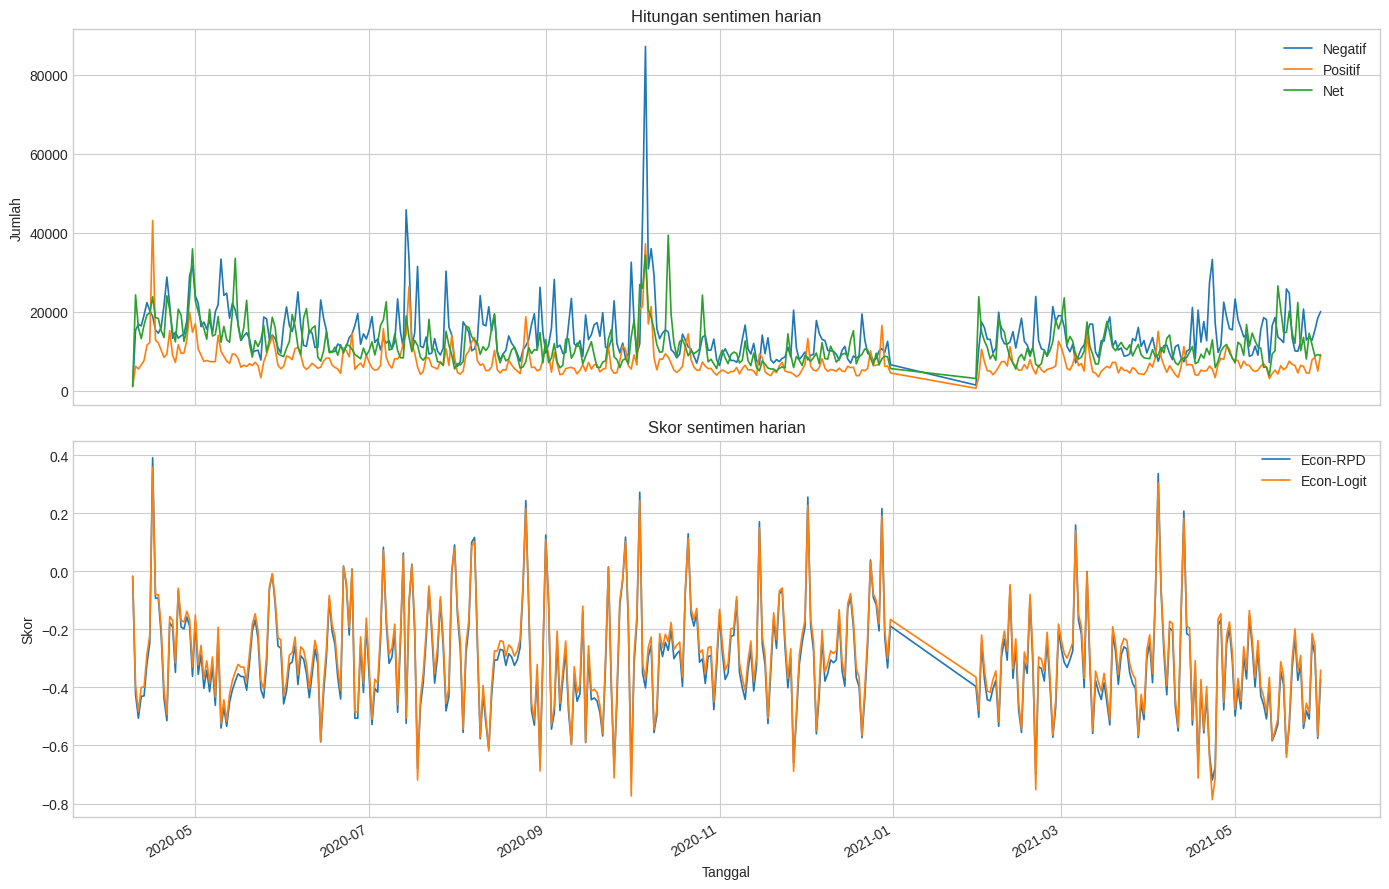

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

df.plot(
    x="Date",
    y=["Econ-Neg", "Econ-Pos", "Net"],
    ax=axes[0],
    linewidth=1.2
)
axes[0].set_title("Hitungan sentimen harian")
axes[0].set_ylabel("Jumlah")
axes[0].legend(["Negatif", "Positif", "Net"])

df.plot(
    x="Date",
    y=["Econ-RPD", "Econ-Logit"],
    ax=axes[1],
    linewidth=1.2
)
axes[1].set_title("Skor sentimen harian")
axes[1].set_ylabel("Skor")
axes[1].set_xlabel("Tanggal")

plt.tight_layout()
plt.show()

Distribusi label sentimen dominan:


,Jumlah Hari
Sentimen,
Negatif,266
Netral,106
Positif,17


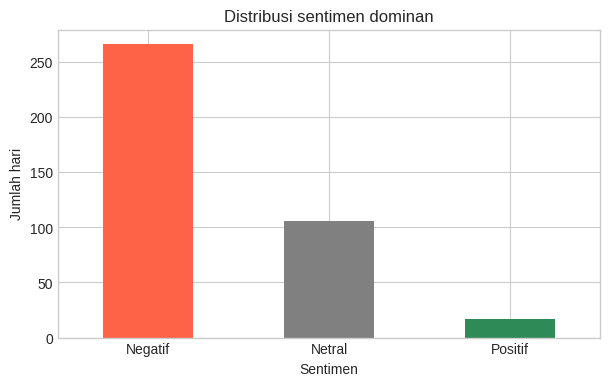

In [ ]:
count_columns = ["Econ-Neg", "Econ-Pos", "Net"]

label_map = {
    "Econ-Neg": "Negatif",
    "Econ-Pos": "Positif",
    "Net": "Netral"
}

df["Sentimen_Dominan"] = (
    df[count_columns]
      .idxmax(axis=1)
      .map(label_map)
)

label_order = ["Negatif", "Netral", "Positif"]
print("Distribusi label sentimen dominan:")
display(
    df["Sentimen_Dominan"]
      .value_counts()
      .reindex(label_order, fill_value=0)
      .rename_axis("Sentimen")
      .to_frame("Jumlah Hari")
)

df["Sentimen_Dominan"].value_counts().reindex(label_order, fill_value=0).plot(
    kind="bar",
    color=["tomato", "gray", "seagreen"],
    figsize=(7, 4)
)
plt.title("Distribusi sentimen dominan")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah hari")
plt.xticks(rotation=0)
plt.show()

In [ ]:
feature_columns = [
    "Econ-Neg",
    "Econ-Pos",
    "Net",
    "Econ-RPD",
    "Econ-Logit"
]

model_df = df[["Date", "Sentimen_Dominan"] + feature_columns].copy()
model_df["Tanggal_Target"] = model_df["Date"].shift(-1)
model_df["Target_Sentimen"] = model_df["Sentimen_Dominan"].shift(-1)
model_df = model_df.dropna().reset_index(drop=True)

X = model_df[feature_columns]
y = model_df["Target_Sentimen"]

print("Jumlah pasangan data:", len(model_df))
display(model_df[["Date", "Tanggal_Target"] + feature_columns + ["Target_Sentimen"]].head())

Jumlah pasangan data: 388


,Date,Tanggal_Target,Econ-Neg,Econ-Pos,Net,Econ-RPD,Econ-Logit,Target_Sentimen
0,2020-04-09,2020-04-10,1074,1035,1194,-0.018492,-0.016056,Netral
1,2020-04-10,2020-04-11,15303,6199,24283,-0.423402,-0.392434,Negatif
2,2020-04-11,2020-04-12,16804,5511,16002,-0.506072,-0.484156,Negatif
3,2020-04-12,2020-04-13,16430,6543,13197,-0.430375,-0.399841,Negatif
4,2020-04-13,2020-04-14,19198,7668,16663,-0.429167,-0.398557,Negatif


In [ ]:
# Pembagian kronologis 75% data awal untuk pelatihan dan 25% data akhir untuk pengujian
split_index = int(len(model_df) * 0.75)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]
tanggal_test = model_df["Tanggal_Target"].iloc[split_index:]

print("Data latih:", len(X_train))
print("Data uji:", len(X_test))
print("Tanggal target pertama pada data uji:", tanggal_test.iloc[0].date())

Data latih: 291
Data uji: 97
Tanggal target pertama pada data uji: 2021-02-24


In [ ]:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

classifier = GaussianNB()
classifier.fit(X_train_scaled, y_train)

print("Model selesai dilatih.")

Model selesai dilatih.


In [ ]:
y_pred = classifier.predict(X_test_scaled)

print("Akurasi:", round(accuracy_score(y_test, y_pred), 4))
print()
print(
    classification_report(
        y_test,
        y_pred,
        labels=label_order,
        zero_division=0
    )
)

Akurasi: 0.6495

              precision    recall  f1-score   support

     Negatif       0.66      0.97      0.78        64
      Netral       0.33      0.03      0.06        30
     Positif       0.00      0.00      0.00         3

    accuracy                           0.65        97
   macro avg       0.33      0.33      0.28        97
weighted avg       0.54      0.65      0.54        97



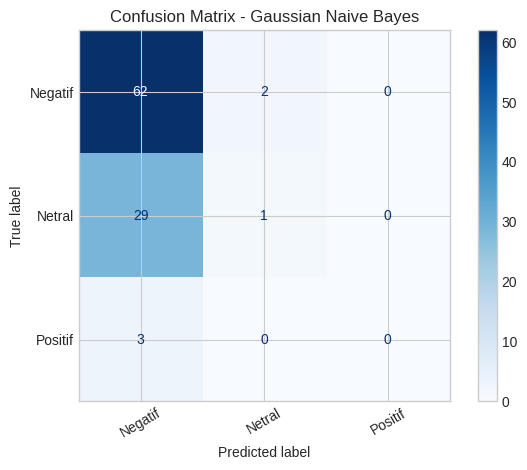

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=label_order)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_order
)
display_matrix.plot(cmap="Blues", values_format="d", xticks_rotation=30)
plt.title("Confusion Matrix - Gaussian Naive Bayes")
plt.tight_layout()
plt.show()

In [ ]:
hasil = pd.DataFrame({
    "Tanggal": tanggal_test.dt.strftime("%Y-%m-%d").to_numpy(),
    "Sentimen_Aktual": y_test.to_numpy(),
    "Sentimen_Prediksi": y_pred
})

display(hasil.head(20))


,Tanggal,Sentimen_Aktual,Sentimen_Prediksi
0,2021-02-24,Netral,Negatif
1,2021-02-25,Negatif,Negatif
2,2021-02-26,Negatif,Negatif
3,2021-02-27,Netral,Negatif
4,2021-02-28,Negatif,Negatif
5,2021-03-01,Negatif,Negatif
6,2021-03-02,Netral,Negatif
7,2021-03-03,Netral,Negatif
8,2021-03-04,Netral,Negatif
9,2021-03-05,Netral,Negatif
